# Telco churn: exploratory analysis

How does the churn rate vary with contract, tenure, price and services? Every rate comes with a
95% Wilson interval, because some groups are small.

Data: IBM Telco Customer Churn sample dataset (Kaggle: blastchar/telco-customer-churn). The company is
fictional and the data's license is unclear (see `docs/data_source.md`), so this notebook shows only
aggregate statistics, never customer rows. `churn` = 1 means the customer left within the last month.
Differences between groups are associations, not causes.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.eda_utils import rate_table, wilson_interval  # noqa: E402

DATA_PATH = ROOT / "data" / "processed" / "telco_clean.parquet"
IMG_DIR = ROOT / "docs" / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> None:
    fig.savefig(IMG_DIR / name, dpi=150, bbox_inches="tight")


def show(table: pd.DataFrame) -> None:
    out = table.drop(columns=["churn_rate", "ci_low", "ci_high"]).copy()
    out["churn_rate_pct"] = (100 * table["churn_rate"]).round(1)
    out["ci_low_pct"] = (100 * table["ci_low"]).round(1)
    out["ci_high_pct"] = (100 * table["ci_high"]).round(1)
    print(out.to_string())


def error_bars(table: pd.DataFrame):
    rates = 100 * table["churn_rate"].to_numpy()
    err = np.vstack([rates - 100 * table["ci_low"].to_numpy(), 100 * table["ci_high"].to_numpy() - rates])
    return rates, err

In [2]:
df = pd.read_parquet(DATA_PATH)
overall = float(df["churn"].mean())
low, high = wilson_interval(int(df["churn"].sum()), len(df))

# The notebook must agree with the audit (docs/raw_data_audit.txt).
assert len(df) == 7_043
assert int(df["churn"].sum()) == 1_869
contracts = df["contract"].value_counts()
assert contracts["Month-to-month"] == 3_875 and contracts["One year"] == 1_473 and contracts["Two year"] == 1_695
assert int((df["internet_service"] == "No").sum()) == 1_526

print(
    f"customers: {len(df):,} | churned: {int(df['churn'].sum()):,} | churn rate: {100 * overall:.2f}% "
    f"(95% interval {100 * float(low):.1f}% to {100 * float(high):.1f}%)"
)

customers: 7,043 | churned: 1,869 | churn rate: 26.54% (95% interval 25.5% to 27.6%)


## 1. Plan and billing: contract, internet service, payment method, paperless billing


contract
                customers  churned  churn_rate_pct  ci_low_pct  ci_high_pct
contract                                                                   
Month-to-month       3875     1655            42.7        41.2         44.3
One year             1473      166            11.3         9.8         13.0
Two year             1695       48             2.8         2.1          3.7

internet_service
                  customers  churned  churn_rate_pct  ci_low_pct  ci_high_pct
internet_service                                                             
Fiber optic            3096     1297            41.9        40.2         43.6
DSL                    2421      459            19.0        17.4         20.6
No                     1526      113             7.4         6.2          8.8

payment_method
                           customers  churned  churn_rate_pct  ci_low_pct  ci_high_pct
payment_method                                                                        
Electronic c

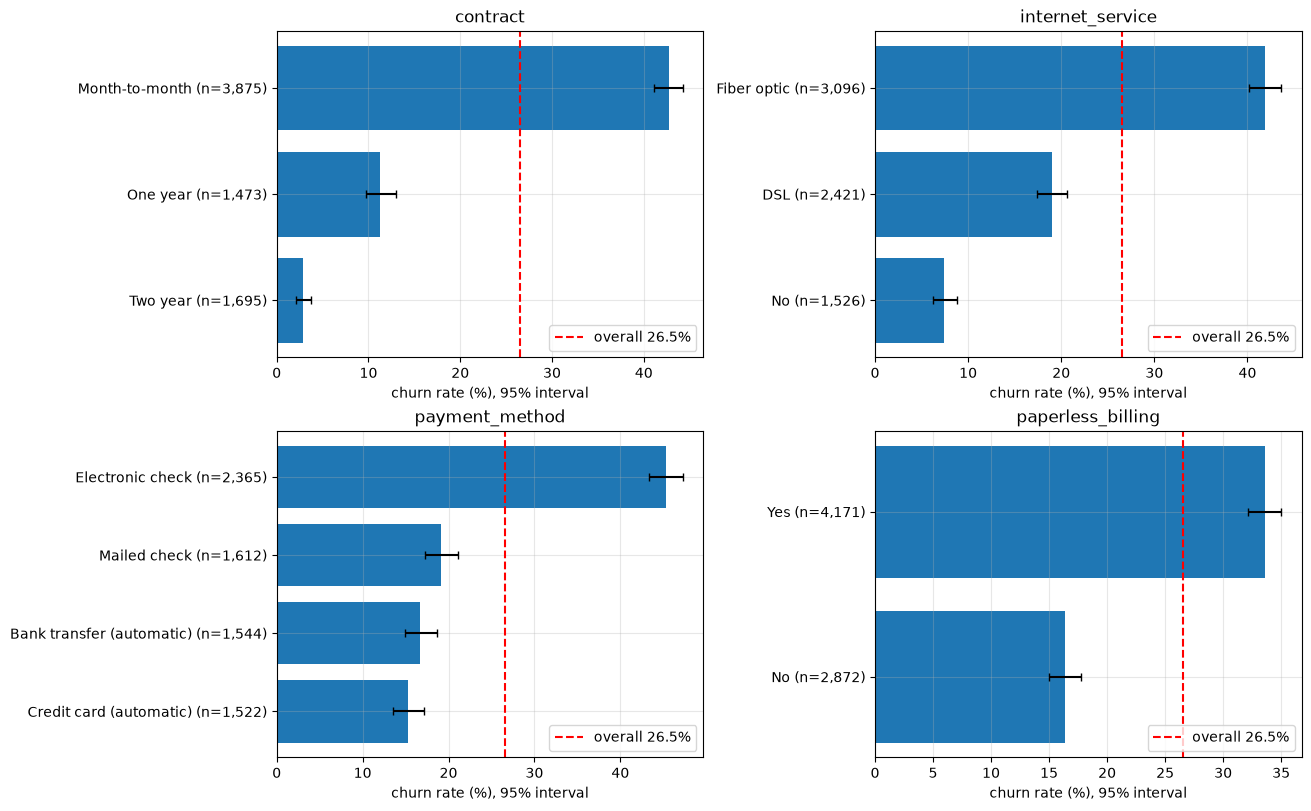

In [3]:
def plot_rates(ax, table: pd.DataFrame, title: str) -> None:
    labels = [f"{idx} (n={n:,})" for idx, n in zip(table.index, table["customers"])]
    rates, err = error_bars(table)
    ax.barh(labels, rates, xerr=err, capsize=3)
    ax.axvline(100 * overall, color="red", linestyle="--", label=f"overall {100 * overall:.1f}%")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("churn rate (%), 95% interval")
    ax.legend(loc="lower right")


features = ["contract", "internet_service", "payment_method", "paperless_billing"]
tables = {col: rate_table(df, col).sort_values("churn_rate", ascending=False) for col in features}

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for ax, (col, table) in zip(axes.ravel(), tables.items()):
    assert table["customers"].sum() == len(df)
    print(f"\n{col}")
    show(table)
    plot_rates(ax, table, col)
save(fig, "01_churn_by_plan_and_billing.png")
plt.show()

## 2. Tenure

Bucket "0" holds the 11 customers with tenure 0 (their `total_charges` was blank in the raw file).

               customers  churned  churn_rate_pct  ci_low_pct  ci_high_pct
tenure_bucket                                                             
0                     11        0             0.0         0.0         25.9
1-6                 1470      784            53.3        50.8         55.9
7-12                 705      253            35.9        32.4         39.5
13-24               1024      294            28.7        26.0         31.6
25-48               1594      325            20.4        18.5         22.4
49-72               2239      213             9.5         8.4         10.8


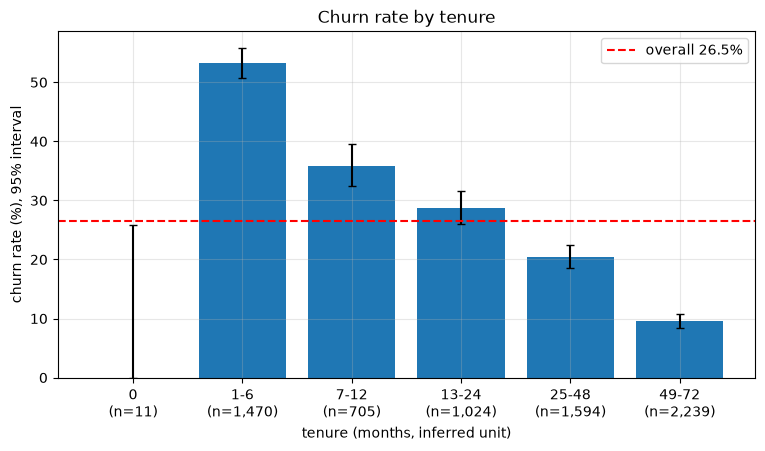

In [4]:
bins = [-1, 0, 6, 12, 24, 48, 72]
labels = ["0", "1-6", "7-12", "13-24", "25-48", "49-72"]
eda = df.assign(tenure_bucket=pd.cut(df["tenure"], bins=bins, labels=labels))

tenure_table = rate_table(eda, "tenure_bucket")
assert tenure_table["customers"].sum() == len(df)
show(tenure_table)

rates, err = error_bars(tenure_table)
fig, ax = plt.subplots()
ax.bar(range(len(tenure_table)), rates, yerr=err, capsize=3)
ax.axhline(100 * overall, color="red", linestyle="--", label=f"overall {100 * overall:.1f}%")
ax.set_xticks(range(len(tenure_table)))
ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(tenure_table.index.astype(str), tenure_table["customers"])])
ax.set_xlabel("tenure (months, inferred unit)")
ax.set_ylabel("churn rate (%), 95% interval")
ax.set_title("Churn rate by tenure")
ax.legend()
save(fig, "02_churn_by_tenure.png")
plt.show()

Contract type and tenure are tangled together, because month-to-month customers tend to have shorter
tenure. This table shows the churn rate (%) and customers for each combination.

In [5]:
by_contract = eda.groupby(["tenure_bucket", "contract"], observed=True)["churn"].agg(
    customers="size", churn_rate_pct="mean"
)
by_contract["churn_rate_pct"] = (100 * by_contract["churn_rate_pct"]).round(1)
print(by_contract.unstack("contract").to_string())

                   customers                   churn_rate_pct                  
contract      Month-to-month One year Two year Month-to-month One year Two year
tenure_bucket                                                                  
0                        NaN      1.0     10.0            NaN      0.0      0.0
1-6                   1413.0     38.0     19.0           55.2     10.5      0.0
7-12                   581.0     85.0     39.0           42.0     10.6      0.0
13-24                  737.0    197.0     90.0           37.7      8.1      0.0
25-48                  802.0    518.0    274.0           32.9     10.6      2.2
49-72                  342.0    634.0   1263.0           26.0     12.9      3.3


## 3. Monthly charges (five equal-sized groups)

            customers  churned  churn_rate_pct  ci_low_pct  ci_high_pct
Q1: 18-25        1420      130             9.2         7.8         10.8
Q2: 25-59        1397      349            25.0        22.8         27.3
Q3: 59-79        1411      420            29.8        27.4         32.2
Q4: 79-94        1407      508            36.1        33.6         38.6
Q5: 94-119       1408      462            32.8        30.4         35.3


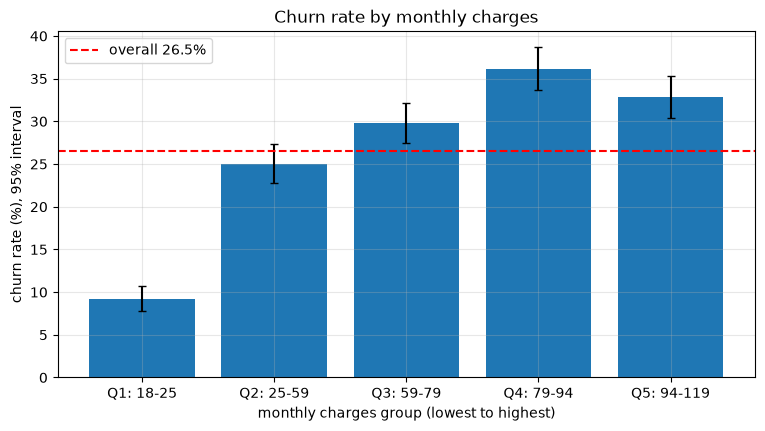


median monthly charges by internet service (price and service type are linked):
internet_service
DSL            56.15
Fiber optic    91.68
No             20.15


In [6]:
quintile = pd.qcut(df["monthly_charges"], 5, labels=False, duplicates="drop")
eda = df.assign(charge_quintile=quintile)
ranges = eda.groupby("charge_quintile")["monthly_charges"].agg(lowest="min", highest="max")
charge_table = rate_table(eda, "charge_quintile").join(ranges)
assert charge_table["customers"].sum() == len(df)
charge_table.index = [
    f"Q{int(i) + 1}: {lo:.0f}-{hi:.0f}"
    for i, lo, hi in zip(charge_table.index, charge_table["lowest"], charge_table["highest"])
]
show(charge_table.drop(columns=["lowest", "highest"]))

rates, err = error_bars(charge_table)
fig, ax = plt.subplots()
ax.bar(range(len(charge_table)), rates, yerr=err, capsize=3)
ax.axhline(100 * overall, color="red", linestyle="--", label=f"overall {100 * overall:.1f}%")
ax.set_xticks(range(len(charge_table)))
ax.set_xticklabels(charge_table.index)
ax.set_xlabel("monthly charges group (lowest to highest)")
ax.set_ylabel("churn rate (%), 95% interval")
ax.set_title("Churn rate by monthly charges")
ax.legend()
save(fig, "03_churn_by_monthly_charges.png")
plt.show()

print("\nmedian monthly charges by internet service (price and service type are linked):")
print(df.groupby("internet_service")["monthly_charges"].median().round(2).to_string())

## 4. Add-on services, among customers with internet service only

Customers without internet cannot have these add-ons, so including them would mix two different groups.

          service has_service  customers  churned  churn_rate  ci_low  ci_high
  online_security         Yes       2019      295        14.6    13.1     16.2
  online_security          No       3498     1461        41.8    40.1     43.4
    online_backup         Yes       2429      523        21.5    19.9     23.2
    online_backup          No       3088     1233        39.9    38.2     41.7
device_protection         Yes       2422      545        22.5    20.9     24.2
device_protection          No       3095     1211        39.1    37.4     40.9
     tech_support         Yes       2044      310        15.2    13.7     16.8
     tech_support          No       3473     1446        41.6    40.0     43.3
     streaming_tv         Yes       2707      814        30.1    28.4     31.8
     streaming_tv          No       2810      942        33.5    31.8     35.3
 streaming_movies         Yes       2732      818        29.9    28.3     31.7
 streaming_movies          No       2785      938   

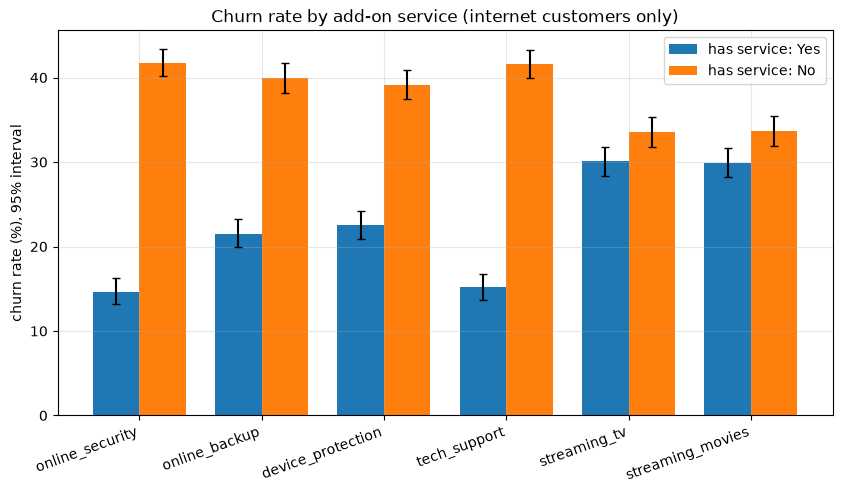

In [7]:
internet = df[df["internet_service"] != "No"]
assert len(internet) == 7_043 - 1_526
addons = ["online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]

rows = []
for col in addons:
    for level in ["Yes", "No"]:
        sub = internet[internet[col] == level]
        k, n = int(sub["churn"].sum()), len(sub)
        lo, hi = wilson_interval(k, n)
        rows.append({
            "service": col, "has_service": level, "customers": n, "churned": k,
            "churn_rate": k / n, "ci_low": float(lo), "ci_high": float(hi),
        })
addon_table = pd.DataFrame(rows)
assert (addon_table.groupby("service")["customers"].sum() == len(internet)).all()

printable = addon_table.copy()
for c in ["churn_rate", "ci_low", "ci_high"]:
    printable[c] = (100 * printable[c]).round(1)
print(printable.to_string(index=False))

x = np.arange(len(addons))
width = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
for i, level in enumerate(["Yes", "No"]):
    sub = addon_table[addon_table["has_service"] == level].set_index("service").loc[addons]
    rates, err = error_bars(sub)
    ax.bar(x + (i - 0.5) * width, rates, width, yerr=err, capsize=3, label=f"has service: {level}")
ax.set_xticks(x)
ax.set_xticklabels(addons, rotation=20, ha="right")
ax.set_ylabel("churn rate (%), 95% interval")
ax.set_title("Churn rate by add-on service (internet customers only)")
ax.legend()
save(fig, "04_churn_by_addon_services.png")
plt.show()

## 5. How related are tenure and charges?

In [8]:
print(df[["tenure", "monthly_charges", "total_charges"]].corr().round(3).to_string())

                 tenure  monthly_charges  total_charges
tenure            1.000            0.248          0.826
monthly_charges   0.248            1.000          0.651
total_charges     0.826            0.651          1.000
